# Лабораторная работа 8. Классификация изображений (классические методы работы с изображениями)

In [1]:
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: E:\study\HSE\3 курс\ML\HSE ML 2026 (7, 8)\lab_01\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import os 
import numpy as np 
import pandas as pd

from skimage.feature import hog 
from skimage.io import imread, imshow
from skimage.transform import resize
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_curve, roc_auc_score, confusion_matrix

from sklearn.neighbors import KNeighborsClassifier

## Датасет: есть кошка / нет кошки

Собрана выборка из 200 фотографий: 100 кошек (метка 1) и 100 собак (метка 0). Собаки выбраны как тематически близкий отрицательный класс.

Источник: [Cats and Dogs, учебный пример TensorFlow](https://www.tensorflow.org/tutorials/images/transfer_learning)

In [3]:
from pathlib import Path

# Объект распознавания — кошка. Отрицательный класс — собаки
data_dir = Path('lab_08_data') / 'cats_vs_dogs'
cats_dir = data_dir / 'cats'
dogs_dir = data_dir / 'dogs'

for folder in [cats_dir, dogs_dir]:
    if not folder.is_dir():
        raise FileNotFoundError(f'Не найдена папка: {folder.resolve()}')


In [4]:
X = []
y = []
filenames = []

for folder, label in [(cats_dir, 1), (dogs_dir, 0)]:
    files = sorted(p for p in folder.iterdir()
                   if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))
    for path in files:
        image = imread(path)
        X.append(image)
        y.append(label)
        filenames.append(path.relative_to(data_dir).as_posix())

y = np.array(y)
filenames = np.array(filenames)

print('Всего изображений:', len(X))
print('Кошек (класс 1):', np.sum(y == 1))
print('Собак (класс 0):', np.sum(y == 0))

assert len(X) == 200
assert np.sum(y == 1) == 100 and np.sum(y == 0) == 100


Всего изображений: 200
Кошек (класс 1): 100
Собак (класс 0): 100


In [5]:
X_resized = []

for image in X:
    resized = resize(image, (100, 100), anti_aliasing=True)
    X_resized.append(resized)

X_resized = np.array(X_resized)

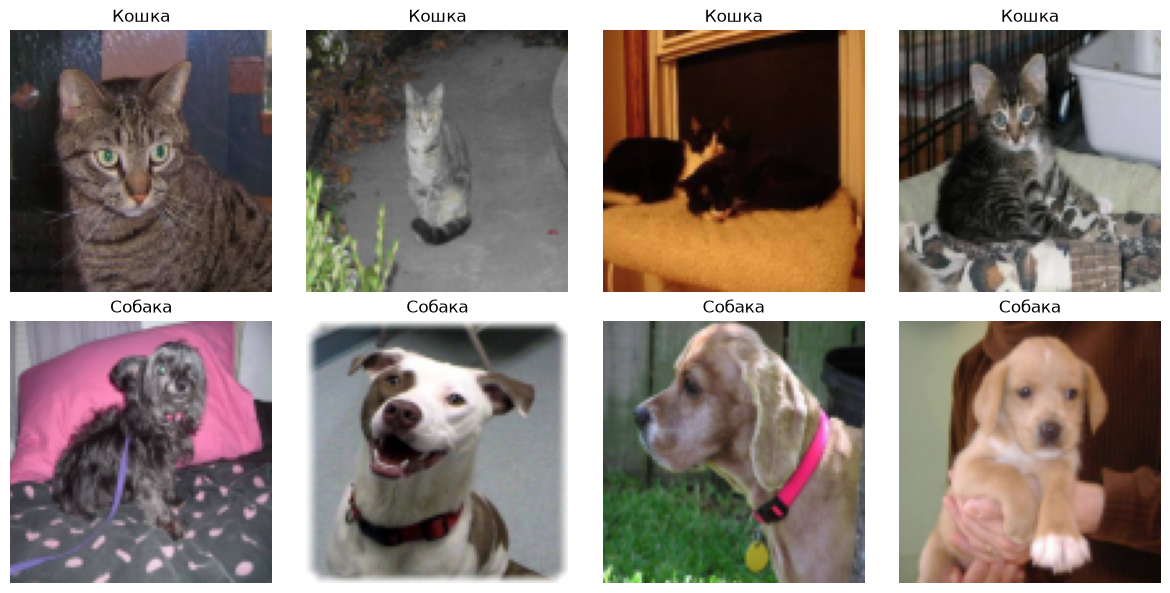

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

indices = [0, 1, 2, 3, 100, 101, 102, 103]

for i, ax in zip(indices, axes.flat):
    ax.imshow(X_resized[i])
    ax.axis('off')
    ax.set_title('Кошка' if y[i] == 1 else 'Собака')

plt.tight_layout()
plt.show()

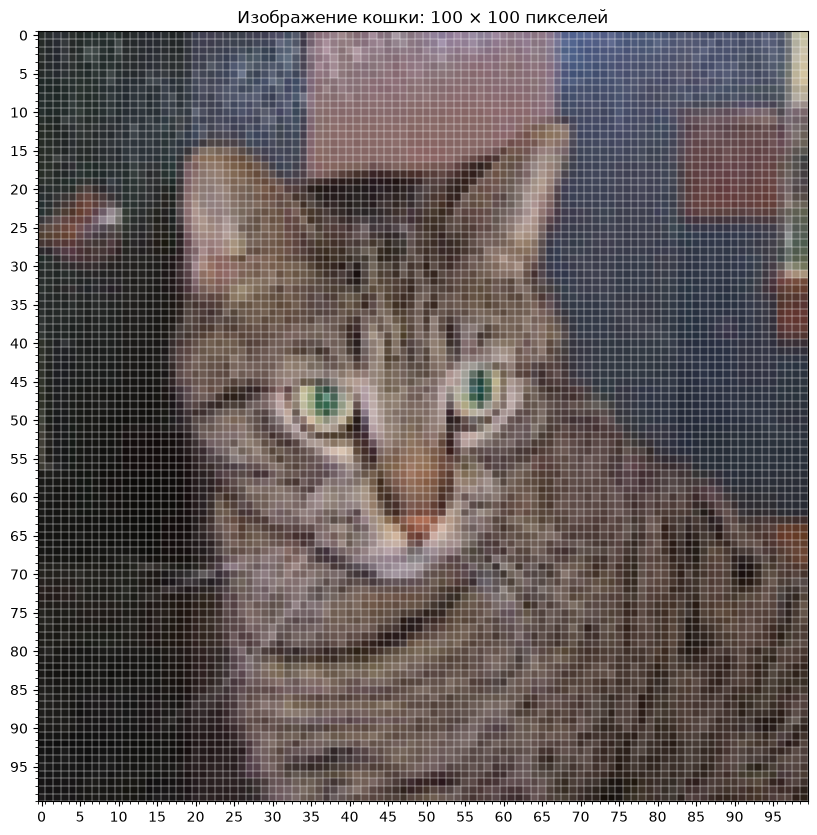

In [7]:
fig, ax = plt.subplots(figsize=(10,10))

ax.imshow(X_resized[0])

ax.set_xticks(np.arange(0, 100, 5))
ax.set_yticks(np.arange(0, 100, 5))

ax.set_xticks(np.arange(-0.5, 100, 1), minor = True)
ax.set_yticks(np.arange(-0.5, 100, 1), minor = True)

ax.grid(which = 'minor', color='white', linestyle='-', linewidth=0.3)

ax.set_title('Изображение кошки: 100 × 100 пикселей')

plt.show()

In [8]:
print('Размер изображения:', X_resized[0].shape)

print('\nЗначение пикселя (10, 20):')
print(X_resized[0][10, 20])

Размер изображения: (100, 100, 3)

Значение пикселя (10, 20):
[0.36434859 0.38685532 0.44965305]


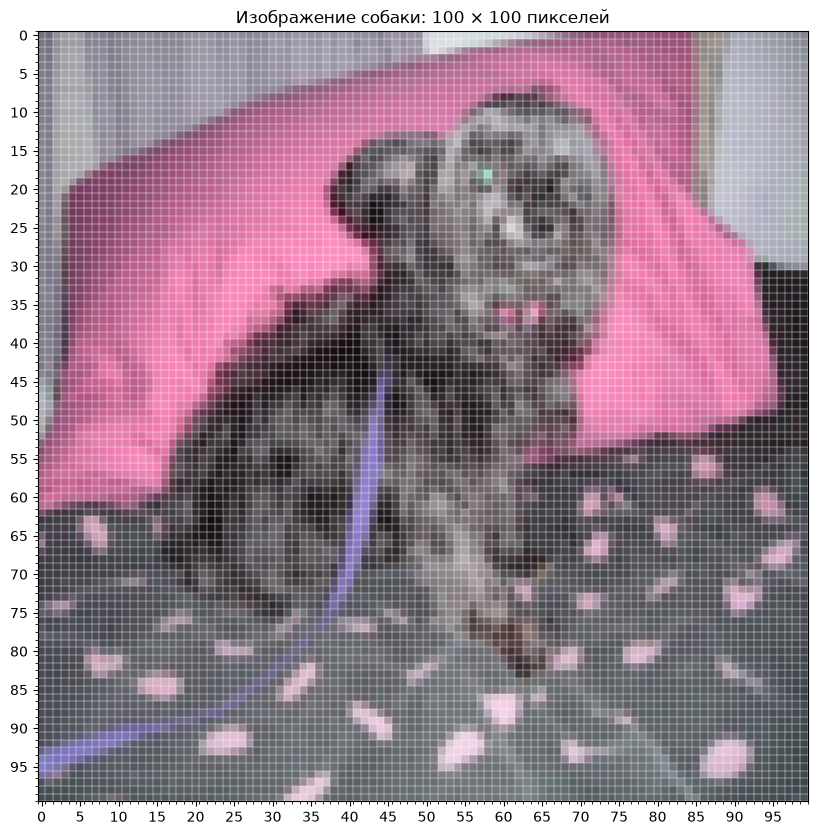

In [9]:
fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(X_resized[100])

ax.set_xticks(np.arange(0, 100, 5))
ax.set_yticks(np.arange(0, 100, 5))

ax.set_xticks(np.arange(-0.5, 100, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 100, 1), minor=True)

ax.grid(which='minor', color='white', linestyle='-', linewidth=0.3)

ax.set_title('Изображение собаки: 100 × 100 пикселей')

plt.show()

In [10]:
print('Размер изображения:', X_resized[100].shape)

print('\nЗначение пикселя (10, 20):')
print(X_resized[100][10, 20])

Размер изображения: (100, 100, 3)

Значение пикселя (10, 20):
[0.62241418 0.58898081 0.64881667]


In [11]:
X_hog = []
y_hog = []

for image, label in zip(X_resized, y): 
    gray = np.dot(image[...,:3], [0.2125, 0.7154, 0.0721])

    features = hog(
        gray, 
        orientations = 9, 
        pixels_per_cell = (8, 8),
        cells_per_block=(2,2),
        block_norm='L2',
        feature_vector = True
    )

    X_hog.append(features)
    y_hog.append(label)

X_hog = np.array(X_hog)
y_hog = np.array(y_hog)

print('Размер матрицы признаков:', X_hog.shape)
print('Размер вектора классов:', y_hog.shape)

Размер матрицы признаков: (200, 4356)
Размер вектора классов: (200,)


In [12]:
print('Количество изображений с кошками:', np.sum(y_hog == 1))
print('Количество изображений с собаками:', np.sum(y_hog == 0))

Количество изображений с кошками: 100
Количество изображений с собаками: 100


## Таблица HOG-признаков

Каждая строка соответствует изображению. Имя файла и метка сохранены вместе с признаками; при обучении используются только числовые HOG-признаки.

In [13]:
df_hog = pd.DataFrame(
    X_hog,
    columns=[f'hog_{i}' for i in range(X_hog.shape[1])]
)
df_hog.insert(0, 'filename', filenames)
df_hog['label'] = y_hog
df_hog.to_csv('lab_08_hog.csv', index=False, encoding='utf-8-sig')

print('Размер таблицы:', df_hog.shape)
display(df_hog.head())

Размер таблицы: (200, 4358)


,filename,hog_0,hog_1,hog_2,hog_3,hog_4,hog_5,hog_6,hog_7,hog_8,...,hog_4347,hog_4348,hog_4349,hog_4350,hog_4351,hog_4352,hog_4353,hog_4354,hog_4355,label
0,cats/cat.1.jpg,0.144086,0.215628,0.017904,0.067967,0.051070,0.281670,0.070193,0.219623,0.127812,...,0.201757,0.320102,0.262901,0.188159,0.152510,0.113982,0.048057,0.098781,0.084383,1
1,cats/cat.112.jpg,0.195593,0.112975,0.027286,0.041813,0.296030,0.109216,0.057793,0.318317,0.111253,...,0.180973,0.084790,0.270424,0.231074,0.253714,0.136807,0.100227,0.148383,0.084118,1
2,cats/cat.114.jpg,0.177900,0.021247,0.000000,0.000000,0.004602,0.000000,0.000000,0.000000,0.224263,...,0.768607,0.334539,0.037934,0.000000,0.019065,0.000000,0.061605,0.086732,0.145983,1
3,cats/cat.12.jpg,0.262790,0.123415,0.019366,0.006506,0.058149,0.036847,0.040610,0.136932,0.250746,...,0.043215,0.058619,0.030974,0.087033,0.112704,0.133956,0.098028,0.162077,0.015291,1
4,cats/cat.128.jpg,0.024446,0.022272,0.027126,0.027716,0.041968,0.015754,0.027186,0.011642,0.062543,...,0.159700,0.084761,0.132666,0.137098,0.159956,0.138777,0.152969,0.184973,0.059625,1


## Разделение на train и test

Оставляем 20% изображений для теста. Стратификация сохраняет доли классов. Все модели используют одно разбиение.

In [14]:
indices = np.arange(len(y_hog))

train_idx, test_idx, y_train, y_test = train_test_split(
    indices, 
    y_hog, 
    test_size = 0.2, 
    random_state = 42, 
    stratify=y_hog
)

X_train = X_hog[train_idx]
X_test = X_hog[test_idx]

print('Обучающая выборка:' ,X_train.shape)
print('Тестовая выборка:' ,X_test.shape)

Обучающая выборка: (160, 4356)
Тестовая выборка: (40, 4356)


## Сравнение трёх методов классификации

Сравним SVM с RBF-ядром, KNN и Random Forest. Для SVM и KNN масштабирование включено в Pipeline: StandardScaler обучается только на train. Параметры заданы до оценки на test, подбор по тестовой выборке не выполняется.

В таблице приведены accuracy и macro-усреднённые precision, recall, F1. Для визуального разбора выберем модель с наибольшей accuracy, при равенстве — с наибольшим F1 macro. Это описательное сравнение на одном разбиении; для независимой оценки выбранной модели понадобились бы новые тестовые данные.

In [15]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

class_names = ['Собака', 'Кошка']  # метки 0 и 1

models = {
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel='rbf', C=1, gamma='scale'))
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=1
    )
}

predictions = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'precision_macro': precision_score(y_test, pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_test, pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_test, pred, average='macro', zero_division=0)
    })

results = pd.DataFrame(rows).sort_values(
    ['accuracy', 'f1_macro'], ascending=False, kind='stable'
).reset_index(drop=True)
results.to_csv('lab_08_model_comparison.csv', index=False, encoding='utf-8-sig')
display(results.round(3))

best_name = results.loc[0, 'model']
best_model = models[best_name]
y_pred = predictions[best_name]
print('Модель для разбора:', best_name)

,model,accuracy,precision_macro,recall_macro,f1_macro
0,SVM (RBF),0.775,0.776,0.775,0.775
1,Random Forest,0.675,0.687,0.675,0.670
2,KNN,0.575,0.671,0.575,0.505


Модель для разбора: SVM (RBF)


## Отчёты и матрицы ошибок

Везде используется порядок: собака — 0, кошка — 1.

SVM (RBF)
              precision    recall  f1-score   support

      Собака       0.79      0.75      0.77        20
       Кошка       0.76      0.80      0.78        20

    accuracy                           0.78        40
   macro avg       0.78      0.78      0.77        40
weighted avg       0.78      0.78      0.77        40

KNN
              precision    recall  f1-score   support

      Собака       0.54      0.95      0.69        20
       Кошка       0.80      0.20      0.32        20

    accuracy                           0.57        40
   macro avg       0.67      0.57      0.51        40
weighted avg       0.67      0.57      0.51        40

Random Forest
              precision    recall  f1-score   support

      Собака       0.73      0.55      0.63        20
       Кошка       0.64      0.80      0.71        20

    accuracy                           0.68        40
   macro avg       0.69      0.68      0.67        40
weighted avg       0.69      0.68      0.67   

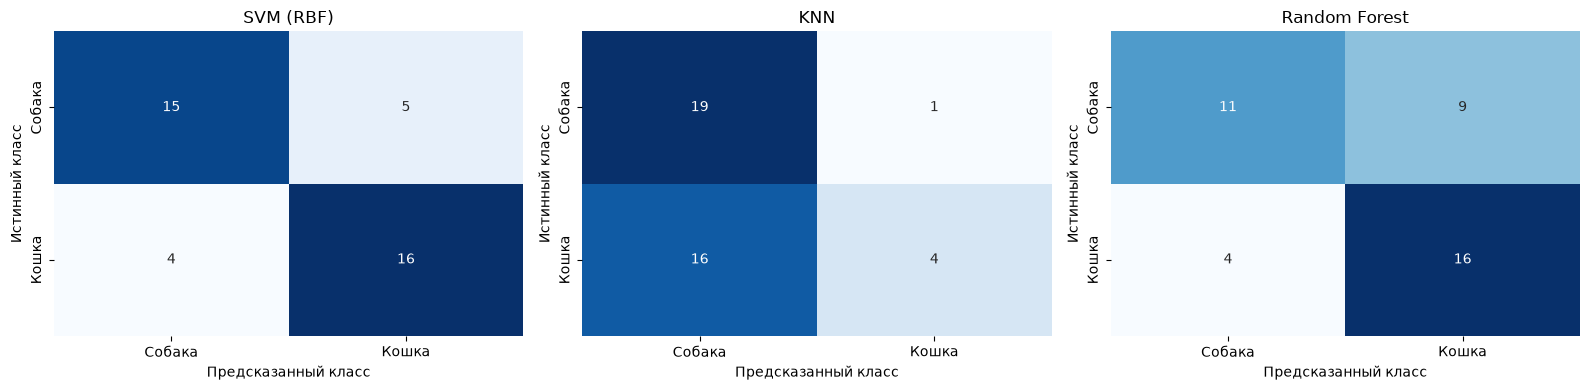

In [16]:
for name, pred in predictions.items():
    print(name)
    print(classification_report(
        y_test, pred, labels=[0, 1], target_names=class_names, zero_division=0
    ))

fig, axes = plt.subplots(1, len(models), figsize=(16, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

## Визуальный разбор предсказаний

Показываем все ошибки выбранной модели и по пять верных предсказаний каждого класса. На изображениях указаны истинная и предсказанная метки, а также имя файла.

Модель: SVM (RBF)
Количество ошибок: 9 из 40


,filename,true_label,predicted_label,correct
0,dogs/dog.37.jpg,0,0,True
1,cats/cat.480.jpg,1,1,True
2,cats/cat.929.jpg,1,1,True
3,cats/cat.930.jpg,1,0,False
4,dogs/dog.245.jpg,0,0,True
5,cats/cat.128.jpg,1,1,True
6,dogs/dog.300.jpg,0,0,True
7,cats/cat.794.jpg,1,1,True
8,cats/cat.635.jpg,1,1,True
9,dogs/dog.876.jpg,0,0,True


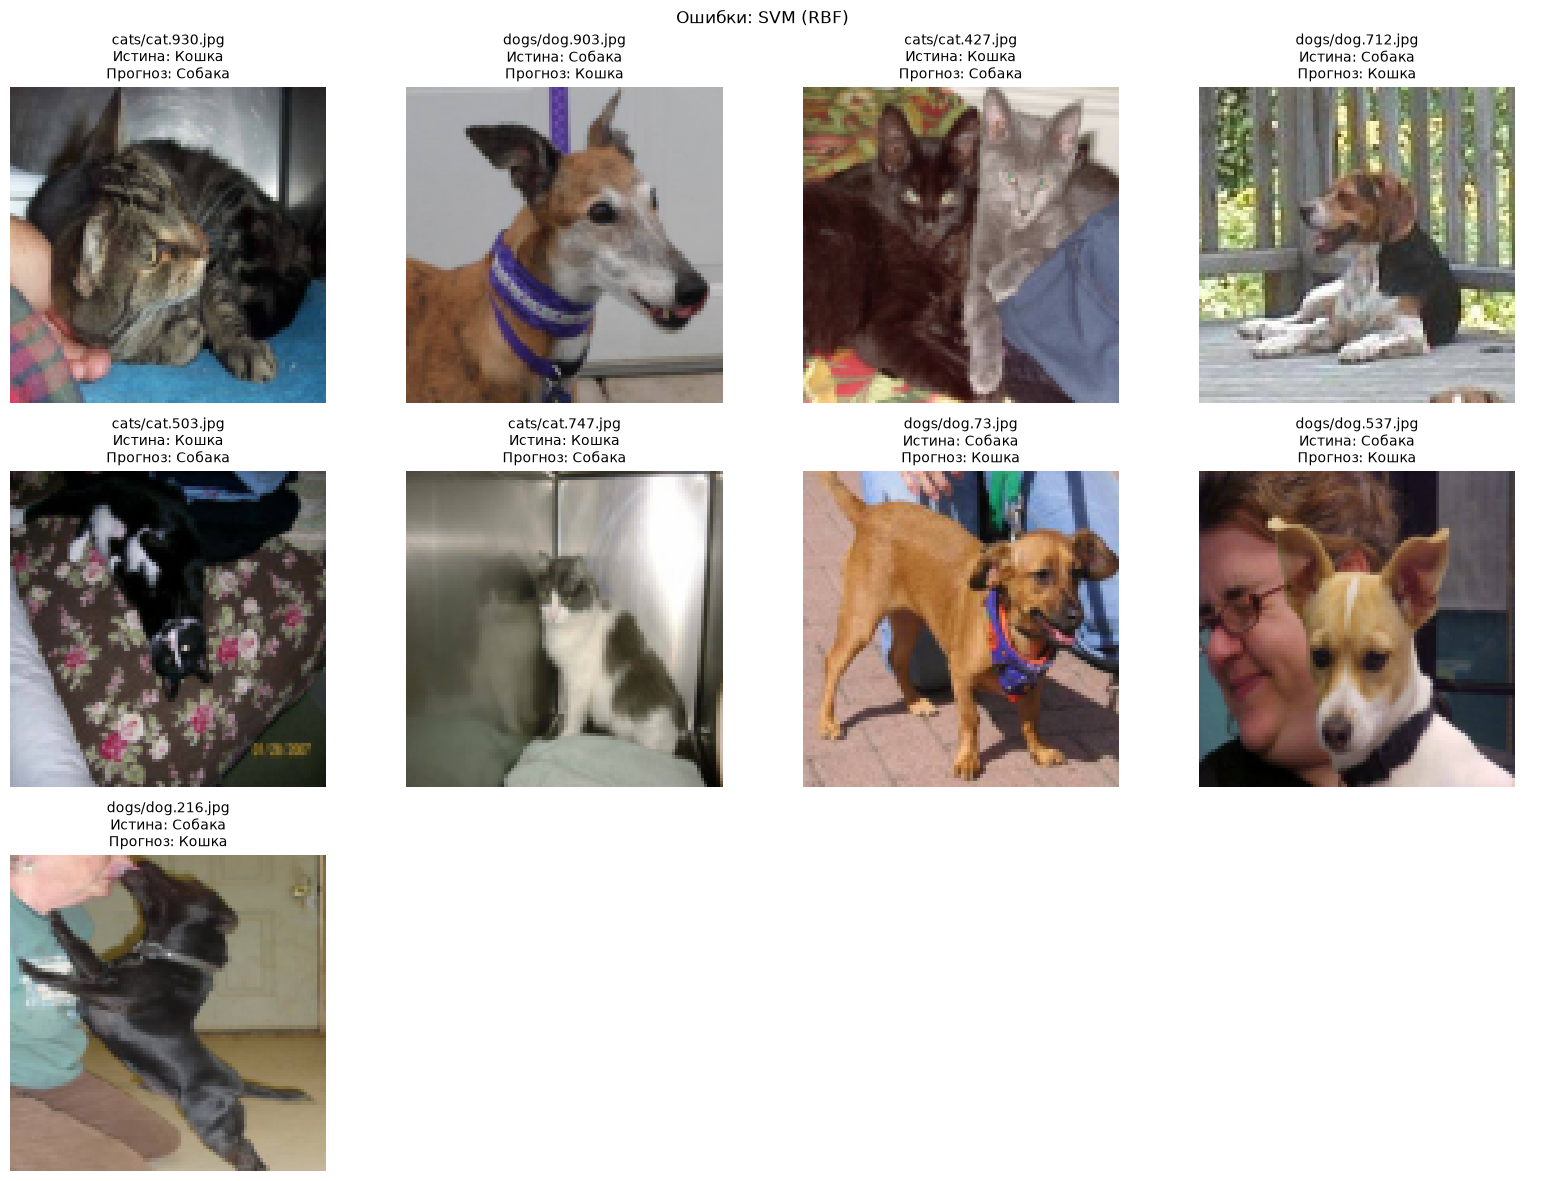

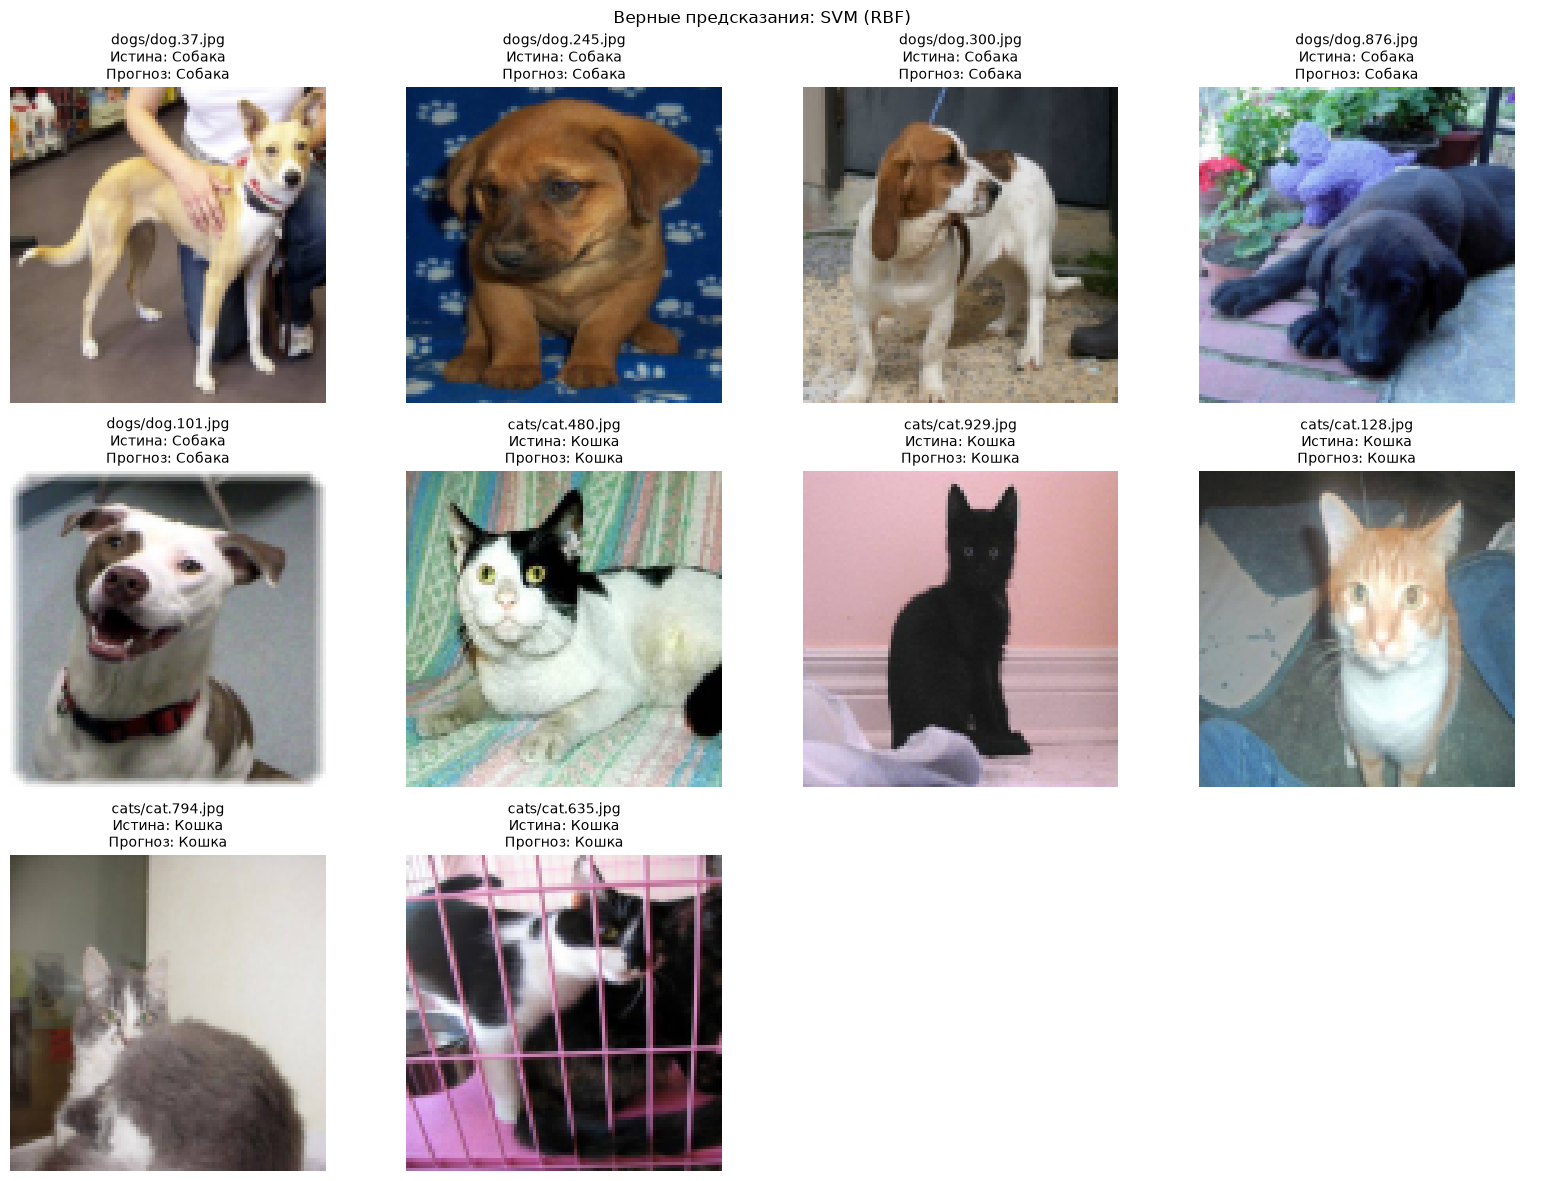

In [17]:
errors = np.flatnonzero(y_test != y_pred)
correct = np.flatnonzero(y_test == y_pred)
print('Модель:', best_name)
print('Количество ошибок:', len(errors), 'из', len(y_test))

test_predictions = pd.DataFrame({
    'filename': filenames[test_idx],
    'true_label': y_test,
    'predicted_label': y_pred,
    'correct': y_test == y_pred
})
display(test_predictions)

def show_predictions(positions, title):
    if len(positions) == 0:
        print(title + ': примеров нет')
        return
    ncols = min(4, len(positions))
    nrows = (len(positions) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)
    for ax, pos in zip(axes.flat, positions):
        original_idx = test_idx[pos]
        ax.imshow(X_resized[original_idx])
        ax.set_title(
            f'{filenames[original_idx]}\n'
            f'Истина: {class_names[y_test[pos]]}\n'
            f'Прогноз: {class_names[y_pred[pos]]}', fontsize=10
        )
        ax.axis('off')
    for ax in axes.flat[len(positions):]:
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_predictions(errors, f'Ошибки: {best_name}')
correct_examples = np.concatenate([
    correct[y_test[correct] == label][:5] for label in [0, 1]
])
show_predictions(correct_examples, f'Верные предсказания: {best_name}')

## Выводы

Для распознавания кошек использованы 100 изображений кошек и 100 изображений собак. После изменения размера до 100 × 100 пикселей каждое изображение представлено вектором из 4356 HOG-признаков. Таблица `lab_08_hog.csv` содержит признаки, имя файла и метку класса. Для обучения выделено 160 изображений, для тестирования — 40, по 20 каждого класса.

На этом разбиении наибольшую accuracy показал SVM с RBF-ядром: 0,775, то есть 31 верное предсказание из 40. Random Forest получил 0,675, KNN — 0,575. F1 macro составляет примерно 0,775, 0,670 и 0,505 соответственно. При этих параметрах SVM лучше остальных различает два класса по HOG-признакам. У него 9 ошибок: 4 кошки определены как собаки, а 5 собак — как кошки.

На ошибочных изображениях встречаются перекрытия и необычные положения головы. В `cat.930.jpg` кошка опустила голову, часть тела закрыта рукой. На `cat.503.jpg` животное показано сверху на узорчатом фоне, а на `cat.427.jpg` рядом находятся две кошки. В `dog.216.jpg` собака вытянулась вверх к человеку, и привычный силуэт изменился. В этих случаях HOG описывает границы всего кадра, включая фон и соседние объекты. Предполагаю, что это мешает выделить признаки самого животного; визуальный просмотр не доказывает причину каждой ошибки.

Не все ошибки связаны со сложным фоном: на `dog.903.jpg` хорошо виден профиль собаки, но модель выбрала кошку. У этой собаки стоячие уши, поэтому отдельные контуры головы могут быть похожи на кошачьи. Это возможное объяснение, которое требует проверки на других изображениях.

Среди верных предсказаний есть фотографии, на которых различимы голова или силуэт одного животного: `cat.480.jpg`, `cat.128.jpg`, `dog.101.jpg`, `dog.300.jpg`. На `cat.929.jpg` чёрная кошка выделяется на светлом фоне, и модель распознаёт её верно. Однако встречаются удачные случаи и с помехами: `cat.635.jpg` распознана через решётку, а `dog.876.jpg` — в лежачем положении. Поэтому отдельный признак вроде наличия решётки или позы сам по себе не определяет успех классификации.

По просмотренным примерам модель справляется с частью кадров, где заметны характерные контуры головы и тела. Ошибки возникают при перекрытиях, нескольких животных в кадре и непривычных ракурсах, но эти наблюдения не являются строгой закономерностью. Для дальнейшего улучшения можно проверить выделение области животного перед HOG и расширить обучающую выборку похожими сложными примерами.

Результаты относятся к одному небольшому тесту. Модель для разбора выбрана после сравнения на этом же тесте, поэтому её результат не является независимой оценкой после выбора. Для более надёжного сравнения следует использовать кросс-валидацию на train и отдельный отложенный test. Отрицательный класс здесь состоит только из собак: работа не проверяет распознавание кошек среди любых возможных объектов.
